In [1]:
import joblib
import pandas as pd
import numpy as np

In [2]:
model = joblib.load("motogp_rf_model.pkl")
features = joblib.load("features.pkl")

In [3]:
new_data = pd.read_excel(
    "PR_2026.ods",
    sheet_name="Arkusz1",
    engine="odf"
)

In [4]:
def lap_time_to_seconds(time_str):
    if pd.isna(time_str):
        return np.nan

    time_str = str(time_str).strip()

    if time_str in ["", "-", "DNS", "DNF", "No Time", "NOT"]:
        return np.nan

    try:
        minutes, seconds = time_str.split(":")
        return int(minutes) * 60 + float(seconds)
    except Exception:
        return np.nan

In [5]:
time_columns = ["FP1", "PR", "FP2"]

for col in time_columns:
    new_data[col] = new_data[col].apply(lap_time_to_seconds)

In [6]:
new_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            22 non-null     int64  
 1   Weekend         22 non-null     object 
 2   Track           22 non-null     object 
 3   Driver          22 non-null     object 
 4   Team            22 non-null     object 
 5   Constructor     22 non-null     object 
 6   FP1             22 non-null     float64
 7   FP1_sky         22 non-null     object 
 8   FP1_temp        22 non-null     int64  
 9   FP1_conditions  22 non-null     object 
 10  FP1_humidity    22 non-null     float64
 11  FP1_ground      22 non-null     int64  
 12  PR              22 non-null     float64
 13  PR_sky          22 non-null     object 
 14  PR_temp         22 non-null     int64  
 15  PR_conditions   22 non-null     object 
 16  PR_humidity     22 non-null     float64
 17  PR_ground       22 non-null     int64

In [7]:
new_data.head()

,Year,Weekend,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,...,FP2,FP2_sky,FP2_temp,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions
0,2026,PORTUGAL,Autódromo Internacional do Algarve,M. Bezzecchi,Aprilia Racing,Aprilia,99.002,Partly Cloudy,18,Dry,...,111.794,Light Rain,17,Wet,0.7,17,Cloudy,19,0.8,Dry
1,2026,PORTUGAL,Autódromo Internacional do Algarve,M. Marquez,Ducati Lenovo Team,Ducati,99.261,Partly Cloudy,18,Dry,...,110.730,Light Rain,17,Wet,0.7,17,Cloudy,19,0.8,Dry
2,2026,PORTUGAL,Autódromo Internacional do Algarve,F. Di Giannantonio,Pertamina Enduro VR46 Racing Team,Ducati,99.463,Partly Cloudy,18,Dry,...,112.236,Light Rain,17,Wet,0.7,17,Cloudy,19,0.8,Dry
3,2026,PORTUGAL,Autódromo Internacional do Algarve,R. Fernandez,SuperFile Trackhouse MotoGP Team,Aprilia,99.411,Partly Cloudy,18,Dry,...,112.148,Light Rain,17,Wet,0.7,17,Cloudy,19,0.8,Dry
4,2026,PORTUGAL,Autódromo Internacional do Algarve,A. Marguez,BK8 Gresini Racing MotoGP,Ducati,99.245,Partly Cloudy,18,Dry,...,110.519,Light Rain,17,Wet,0.7,17,Cloudy,19,0.8,Dry


In [8]:
print(new_data[features])

    Year                                Track              Driver  \
0   2026  Autódromo Internacional do Algarve         M. Bezzecchi   
1   2026  Autódromo Internacional do Algarve           M. Marquez   
2   2026  Autódromo Internacional do Algarve   F. Di Giannantonio   
3   2026  Autódromo Internacional do Algarve         R. Fernandez   
4   2026  Autódromo Internacional do Algarve           A. Marguez   
5   2026  Autódromo Internacional do Algarve            P. Acosta   
6   2026  Autódromo Internacional do Algarve            J. Martin   
7   2026  Autódromo Internacional do Algarve          F. Aldeguer   
8   2026  Autódromo Internacional do Algarve             J. Zarco   
9   2026  Autódromo Internacional do Algarve            B. Binder   
10  2026  Autódromo Internacional do Algarve           D. Moreira   
11  2026  Autódromo Internacional do Algarve           I. Lecuona   
12  2026  Autódromo Internacional do Algarve            J. Miller   
13  2026  Autódromo Internacional 

In [9]:
missing = new_data.isna().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [10]:
new_data = new_data[features]

pred = model.predict(new_data)

new_data["Predicted_Q"] = pred

In [11]:
def seconds_to_laptime(sec):
    minutes = int(sec // 60)
    seconds = sec % 60
    return f"{minutes}:{seconds:06.3f}"

new_data["Predicted_Q_Time"] = new_data["Predicted_Q"].apply(seconds_to_laptime)

In [12]:
new_data.sort_values("Predicted_Q")

,Year,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,FP1_humidity,...,FP2_temp,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions,Predicted_Q,Predicted_Q_Time
3,2026,Autódromo Internacional do Algarve,R. Fernandez,SuperFile Trackhouse MotoGP Team,Aprilia,99.411,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.451287,1:38.451
0,2026,Autódromo Internacional do Algarve,M. Bezzecchi,Aprilia Racing,Aprilia,99.002,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.457373,1:38.457
6,2026,Autódromo Internacional do Algarve,J. Martin,Aprilia Racing,Aprilia,99.144,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.469340,1:38.469
5,2026,Autódromo Internacional do Algarve,P. Acosta,Red Bull KTM Factory Racing,KTM,99.618,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.484733,1:38.485
8,2026,Autódromo Internacional do Algarve,J. Zarco,Castrol Honda LCR,Honda,100.013,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.489513,1:38.490
1,2026,Autódromo Internacional do Algarve,M. Marquez,Ducati Lenovo Team,Ducati,99.261,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.496727,1:38.497
9,2026,Autódromo Internacional do Algarve,B. Binder,Red Bull KTM Factory Racing,KTM,99.929,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.511210,1:38.511
14,2026,Autódromo Internacional do Algarve,A. Ogura,SuperFile Trackhouse MotoGP Team,Aprilia,100.001,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,18,0.0083,Dry,98.512027,1:38.512
4,2026,Autódromo Internacional do Algarve,A. Marguez,BK8 Gresini Racing MotoGP,Ducati,99.245,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.521060,1:38.521
7,2026,Autódromo Internacional do Algarve,F. Aldeguer,BK8 Gresini Racing MotoGP,Ducati,99.513,Partly Cloudy,18,Dry,0.6,...,17,Wet,0.7,17,Cloudy,19,0.8000,Dry,98.521670,1:38.522


In [13]:
actual_data = pd.read_excel(
    "PR_2026.ods",
    sheet_name="Arkusz2",
    engine="odf"
)

In [14]:
time_columns = ["FP1", "PR", "FP2", "Q"]

for col in time_columns:
    actual_data[col] = actual_data[col].apply(lap_time_to_seconds)

time_columns = ["FP1", "PR", "FP2"]

for col in time_columns:
    new_data[col] = new_data[col].apply(lap_time_to_seconds)

In [15]:
new_data["Error"] = new_data["Predicted_Q"] - actual_data["Q"]
new_data["Abs_Error"] = abs(new_data["Error"])

comparison = new_data[
    ["Driver", "Predicted_Q_Time", "Error", "Abs_Error"]
].sort_values("Error")

print(comparison.to_string(index=False))

            Driver Predicted_Q_Time      Error  Abs_Error
     E. Bastianini         1:38.560 -12.673120  12.673120
     F. Morbidelli         1:39.372  -9.395427   9.395427
     F. Quartararo         1:38.648  -4.318397   4.318397
           A. Rins         1:38.991  -3.805207   3.805207
          J. Dixon         1:38.879  -3.506287   3.506287
          A. Ogura         1:38.512  -3.421973   3.421973
         J. Miller         1:38.675  -3.174943   3.174943
      P. Espargaro         1:39.591  -3.008113   3.008113
         L. Marini         1:39.039  -2.847237   2.847237
      A. Fernandez         1:39.584  -2.735127   2.735127
        D. Moreira         1:38.530  -0.337280   0.337280
         B. Binder         1:38.511  -0.194790   0.194790
          J. Zarco         1:38.490  -0.140487   0.140487
       F. Aldeguer         1:38.522   0.006670   0.006670
         J. Martin         1:38.469   0.155340   0.155340
         P. Acosta         1:38.485   0.180733   0.180733
        A. Mar

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(actual_data["Q"], new_data["Predicted_Q"])
rmse = np.sqrt(mean_squared_error(actual_data["Q"], new_data["Predicted_Q"]))

print(f"MAE:  {mae:.3f} s")
print(f"RMSE: {rmse:.3f} s")

MAE:  2.443 s
RMSE: 3.955 s


In [17]:
new_data["Actual_Position"] = actual_data["Q"].rank(method="min").astype(int)
new_data["Predicted_Position"] = new_data["Predicted_Q"].rank(method="min").astype(int)

comparison = new_data[
    ["Driver", "Predicted_Q",
     "Actual_Position", "Predicted_Position"]
].sort_values("Actual_Position")

print(comparison.to_string(index=False))

            Driver  Predicted_Q  Actual_Position  Predicted_Position
      M. Bezzecchi    98.457373                1                   2
        M. Marquez    98.496727                2                   6
F. Di Giannantonio    98.548650                3                  12
      R. Fernandez    98.451287                4                   1
        A. Marguez    98.521060                5                   9
         P. Acosta    98.484733                6                   4
         J. Martin    98.469340                7                   3
       F. Aldeguer    98.521670                8                  10
          J. Zarco    98.489513                9                   5
         B. Binder    98.511210               10                   7
        D. Moreira    98.529720               11                  11
        I. Lecuona    99.567497               12                  20
         J. Miller    98.675057               13                  15
         L. Marini    99.038763   

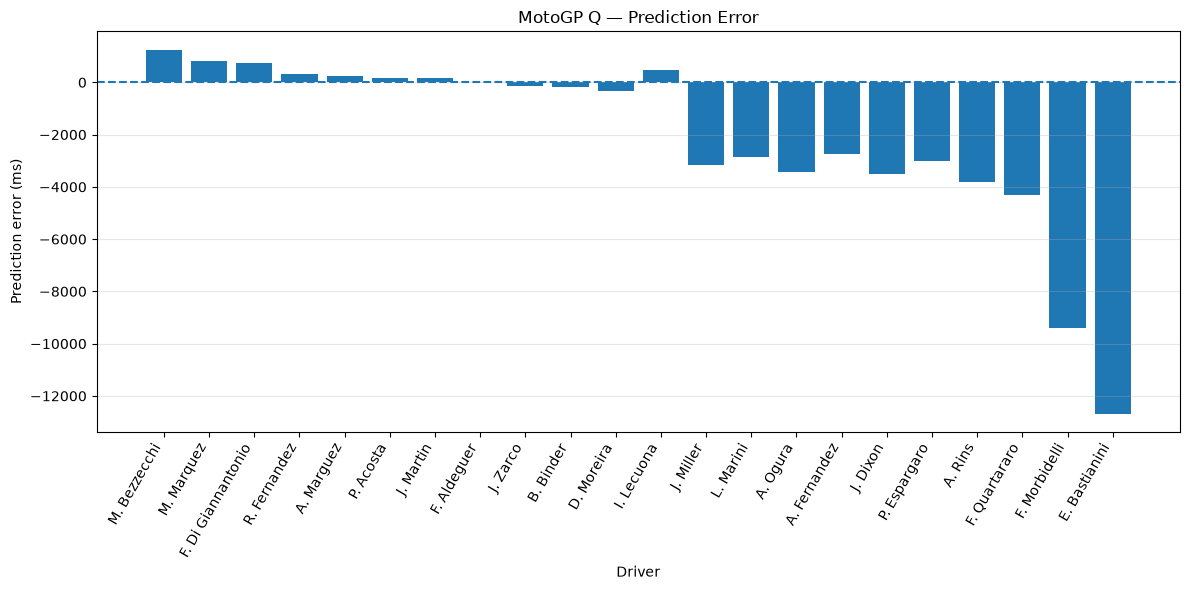

In [18]:
import matplotlib.pyplot as plt

plot_data = actual_data.sort_values("Q").reset_index(drop=True)

plot_data["Error_ms"] = (
    new_data["Predicted_Q"] - plot_data["Q"]
) * 1000

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data["Driver"],
    plot_data["Error_ms"]
)

plt.axhline(0, linestyle="--")

plt.ylabel("Prediction error (ms)")
plt.xlabel("Driver")
plt.title("MotoGP Q — Prediction Error")

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()